# Diffusion Models

This notebook has a minimal smoke test for loading the main diffusion backbones and generating a few example images with standard sampling.

For details about the model configurations and sampling pipeline, see the `src/model_utils.py` file.

In [1]:
from src.model_utils import *
from IPython.display import display
from PIL import Image

PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "smoke_test_examples"
SEED = 42

/home/lenka-hake/Documents/GM/generative-modelling/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:187: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12080). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0
[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install

# Model Configurations

In [2]:
list_model_configs()

{'sdxl': {'model_id': 'stabilityai/stable-diffusion-xl-base-1.0',
  'num_inference_steps': 50,
  'guidance_scale': 5.5,
  'height': 1024,
  'width': 1024},
 'dreamshaper-xl-v2-turbo': {'model_id': 'Lykon/dreamshaper-xl-v2-turbo',
  'num_inference_steps': 4,
  'guidance_scale': 3.5,
  'height': 1024,
  'width': 1024}}

# Example Prompts

In [3]:
example_prompts = [
    "An elephant in a room full of glassware.",
    # "A dog buying groceries.",
    # "A heart-shaped light blue bomb that explodes inside a pancake."
]

# SDXL Example

### Load the Model

In [4]:
pipeline_sdxl = load_pipeline_standard(SDXL)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

### Generate Images

In [5]:
result_sdxl = generate_images_standard(
    pipeline_sdxl,
    example_prompts,
    SDXL,
    seed=SEED,
    output_dir=OUTPUT_DIR
)

result_sdxl

  0%|          | 0/50 [00:00<?, ?it/s]

[PosixPath('/home/lenka-hake/Documents/GM/generative-modelling/outputs/smoke_test_examples/sdxl_000_20260516_230921.png')]

### Display One Example

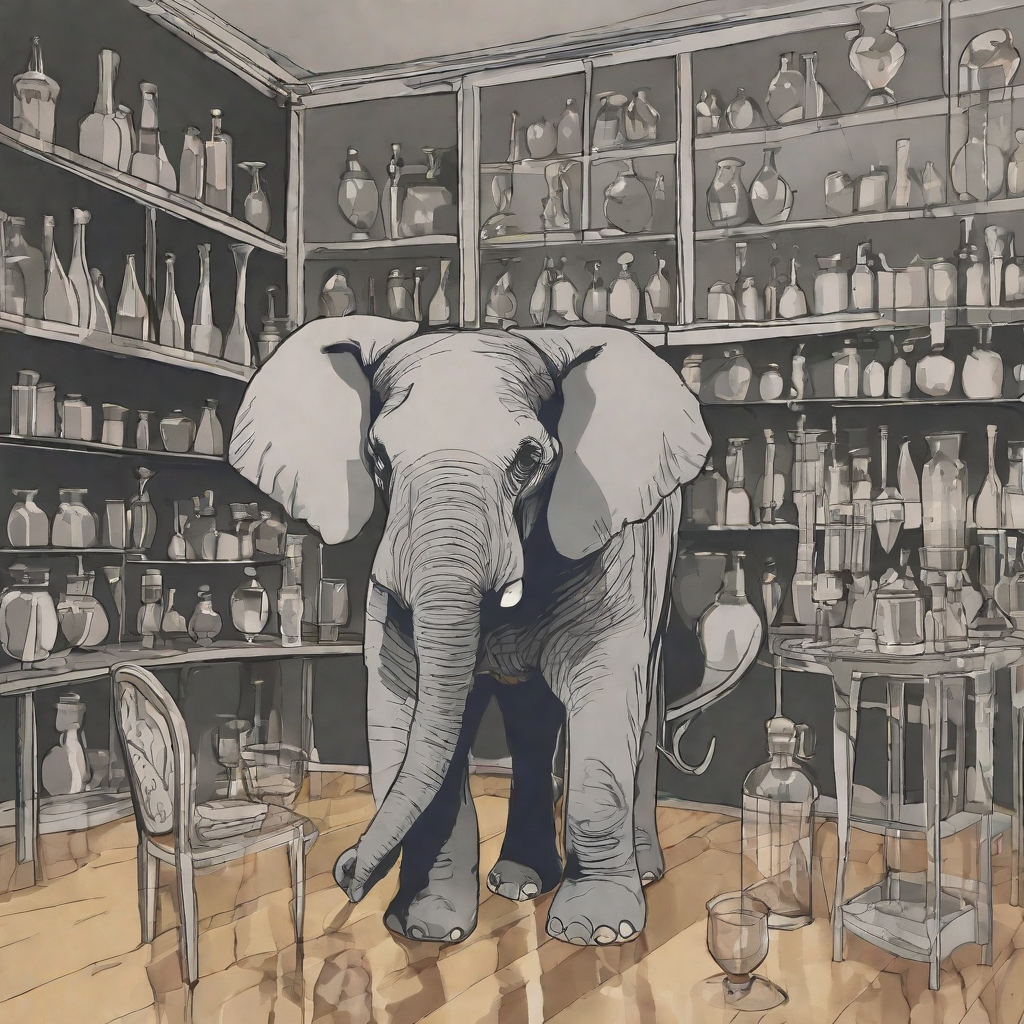

In [6]:
display(Image.open(result_sdxl[0]))

### Free Memory Before Loading Another Model

In [7]:
free_pipeline(pipeline_sdxl)
pipeline_sdxl = None

# DreamSharper XL Turbo Example

### Load the Model

In [8]:
pipeline_dream_sharper = load_pipeline_standard(DREAM_SHARPER)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

### Generate Images

In [9]:
result_dream_sharper = generate_images_standard(
    pipeline_dream_sharper,
    example_prompts,
    DREAM_SHARPER,
    seed=SEED,
    output_dir=OUTPUT_DIR
)

result_dream_sharper

  0%|          | 0/4 [00:00<?, ?it/s]

[PosixPath('/home/lenka-hake/Documents/GM/generative-modelling/outputs/smoke_test_examples/dreamshaper-xl-v2-turbo_000_20260516_231309.png')]

### Display One Example

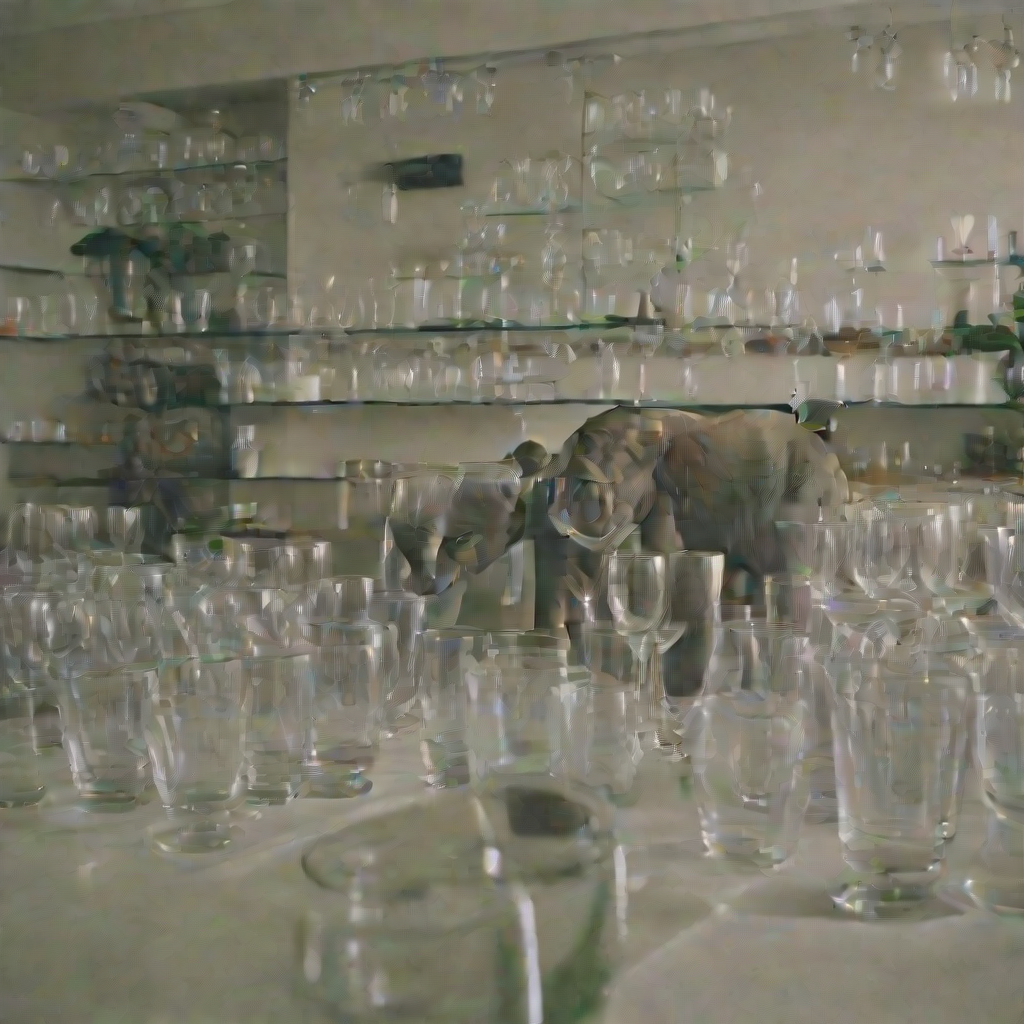

In [10]:
display(Image.open(result_dream_sharper[0]))

### Free Memory Before Loading Another Model

In [11]:
free_pipeline(pipeline_dream_sharper)
pipeline_dream_sharper = None